## Soil Sustainability Analysis for Nebraska Fields

This notebook analyzes soil health indicators for 5 agricultural fields in Nebraska using USDA SSURGO (Soil Survey Geographic) data.

### Data Source
- **Provider**: USDA NRCS Soil Data Access (SDA) REST API
- **Endpoint**: https://sdmdataaccess.sc.egov.usda.gov/
- **Database**: SSURGO (Soil Survey Geographic Database)

### Field Coordinates

| Field ID | Latitude | Longitude | Location |
|----------|---------|-----------|----------|
| field_001 | 40.92336 | -96.3735 | Near Crete, NE (Saline County) |
| field_002 | 40.92459 | -96.38387 | Near Crete, NE (Saline County) |
| field_003 | 40.91862 | -96.36465 | Near Crete, NE (Saline County) |
| field_004 | 40.95425 | -96.0716 | Near Ashland, NE (Saunders County) |
| field_005 | 41.01814 | -96.07927 | Near Ashland, NE (Saunders County) |

### Key Soil Health Indicators

| Parameter | Description | Units | Optimal Range |
|-----------|-------------|-------|---------------|
| om_r | Organic matter | % | 3.0 - 5.0 |
| ph1to1h2o_r | Soil pH (1:1 water) | pH | 6.5 - 7.0 |
| cec7_r | Cation exchange capacity | meq/100g | 15 - 30 |

### Soil Health Score Methodology
- **pH Score**: Peaks at 6.5-7.0, decreases toward extremes
- **OM Score**: Higher is better (0-6% normalized)
- **CEC Score**: Higher is better (5-40 meq/100g normalized)
- **Composite Score**: Equal weighting (33.3% each)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.insert(0, str(Path('../skills/my-farm-advisor/soil/ssurgo-soil/src').resolve()))

from ssurgo_soil import get_soil_at_point

## Define Field Coordinates

In [2]:
fields = {
    'field_001': {'lat': 40.92336, 'lon': -96.3735},
    'field_002': {'lat': 40.92459, 'lon': -96.38387},
    'field_003': {'lat': 40.91862, 'lon': -96.36465},
    'field_004': {'lat': 40.95425, 'lon': -96.0716},
    'field_005': {'lat': 41.01814, 'lon': -96.07927},
}

print(f"Loaded {len(fields)} fields for soil analysis")

Loaded 5 fields for soil analysis


## Query SSURGO Soil Data for Each Field

In [3]:
all_soil_data = []

for field_id, coords in fields.items():
    print(f"Querying soil data for {field_id}...")
    try:
        soil_data = get_soil_at_point(
            lon=coords['lon'],
            lat=coords['lat']
        )
        soil_data['field_id'] = field_id
        all_soil_data.append(soil_data)
        print(f"  -> Retrieved {len(soil_data)} soil records")
    except Exception as e:
        print(f"  -> Error: {e}")

soil_df = pd.concat(all_soil_data, ignore_index=True)
print(f"\nTotal soil records retrieved: {len(soil_df)}")

Querying soil data for field_001...


  -> Retrieved 11 soil records
Querying soil data for field_002...


  -> Retrieved 11 soil records
Querying soil data for field_003...


  -> Retrieved 9 soil records
Querying soil data for field_004...


  -> Retrieved 3 soil records
Querying soil data for field_005...


  -> Retrieved 2 soil records

Total soil records retrieved: 36


## Filter for Key Soil Health Indicators

In [4]:
key_columns = ['field_id', 'mukey', 'muname', 'compname', 'comppct_r', 
               'om_r', 'ph1to1h2o_r', 'cec7_r', 'hzdept_r', 'hzdepb_r', 
               'claytotal_r', 'dbthirdbar_r']

soil_filtered = soil_df[key_columns].copy()

soil_filtered = soil_filtered.rename(columns={
    'om_r': 'organic_matter_pct',
    'ph1to1h2o_r': 'ph',
    'cec7_r': 'cec',
    'hzdept_r': 'horizon_top',
    'hzdepb_r': 'horizon_bottom',
    'claytotal_r': 'clay_pct',
    'dbthirdbar_r': 'bulk_density'
})

# Calculate topsoil depth for each horizon
soil_filtered['topsoil_depth'] = soil_filtered['horizon_bottom'] - soil_filtered['horizon_top']

print(f"Filtered to {len(soil_filtered)} records with key indicators")
print("\nSample data:")
soil_filtered.head(10)

Filtered to 36 records with key indicators

Sample data:


,field_id,mukey,muname,compname,comppct_r,organic_matter_pct,ph,cec,horizon_top,horizon_bottom,clay_pct,bulk_density,topsoil_depth
0,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Yutan,85,2.30,5.9,29.2,0,18,36.0,1.45,18
1,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Yutan,85,0.90,6.7,26.7,18,33,34.0,1.42,15
2,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Judson,8,3.00,6.5,21.9,0,18,26.0,1.24,18
3,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Judson,8,2.75,6.5,23.4,18,64,28.0,1.30,46
4,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Morrill,4,2.00,5.8,22.3,0,18,27.0,1.39,18
5,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Morrill,4,1.50,5.8,22.8,18,27,28.0,1.36,9
6,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Morrill,4,1.00,6.5,25.3,27,72,32.0,1.45,45
7,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Wymore,2,3.00,6.0,27.8,0,18,35.0,1.30,18
8,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Wymore,2,2.50,6.0,29.7,18,30,38.0,1.35,12
9,field_001,1691498,"Yutan silty clay loam, 6 to 11 percent slopes,...",Aquolls,1,3.00,5.8,24.4,0,15,30.0,1.28,15


## Aggregate Soil Properties by Field

Since each field may have multiple soil components, we weight the values by component percentage (comppct_r) to get a representative field-level value.

In [5]:
def weighted_avg(group, value_col, weight_col):
    """Calculate weighted average."""
    weights = group[weight_col].fillna(0)
    values = group[value_col].fillna(0)
    if weights.sum() == 0:
        return np.nan
    return (values * weights).sum() / weights.sum()

field_soil = soil_filtered.groupby('field_id').apply(
    lambda x: pd.Series({
        'organic_matter_pct': weighted_avg(x, 'organic_matter_pct', 'comppct_r'),
        'ph': weighted_avg(x, 'ph', 'comppct_r'),
        'cec': weighted_avg(x, 'cec', 'comppct_r'),
        'clay_pct': weighted_avg(x, 'clay_pct', 'comppct_r'),
        'bulk_density': weighted_avg(x, 'bulk_density', 'comppct_r'),
        'topsoil_depth': weighted_avg(x, 'topsoil_depth', 'comppct_r'),
        'n_components': len(x)
    })
).reset_index()

print("Aggregated soil properties by field:")
field_soil

Aggregated soil properties by field:


,field_id,organic_matter_pct,ph,cec,clay_pct,bulk_density,topsoil_depth,n_components
0,field_001,1.727941,6.289706,27.260784,34.014706,1.416324,18.137255,11.0
1,field_002,1.727941,6.289706,27.260784,34.014706,1.416324,18.137255,11.0
2,field_003,3.095122,6.104878,26.317073,32.902439,1.354390,14.926829,9.0
3,field_004,3.090000,6.625000,22.915000,22.635000,1.287000,149.070000,3.0
4,field_005,1.950000,6.300000,26.150000,33.000000,1.320000,75.000000,2.0


## Erosion Risk Assessment

Using clay content as a proxy for erosion risk:
- Lower clay content = higher erosion risk (less protection)
- Higher clay content = lower erosion risk (better aggregation)

Scoring: 0 (highest risk) to 1 (lowest risk)

In [6]:
def score_erosion_risk(clay_pct):
    """Score erosion risk: higher clay = lower risk.
    
    Clay protects soil from erosion by improving aggregation.
    Typical range: 5-60% clay.
    """
    if pd.isna(clay_pct):
        return np.nan
    # Normalize: 5% clay = high risk (0), 40%+ clay = low risk (1)
    return min(1.0, max(0, (clay_pct - 5) / 35))

field_soil['erosion_risk_score'] = field_soil['clay_pct'].apply(score_erosion_risk)

# Categorize erosion risk
def erosion_category(score):
    if pd.isna(score):
        return 'Unknown'
    elif score >= 0.7:
        return 'Low'
    elif score >= 0.4:
        return 'Moderate'
    else:
        return 'High'

field_soil['erosion_category'] = field_soil['erosion_risk_score'].apply(erosion_category)

print("Erosion Risk Assessment:")
print(field_soil[['field_id', 'clay_pct', 'erosion_risk_score', 'erosion_category']].to_string(index=False))

Erosion Risk Assessment:
 field_id  clay_pct  erosion_risk_score erosion_category
field_001 34.014706            0.828992              Low
field_002 34.014706            0.828992              Low
field_003 32.902439            0.797213              Low
field_004 22.635000            0.503857         Moderate
field_005 33.000000            0.800000              Low


## Carbon Storage Potential

Carbon storage potential based on:
- Organic matter percentage
- Topsoil depth (cm)
- Bulk density (g/cm³)

Formula: `Carbon Index = OM × Topsoil Depth × Bulk Density`
Normalized to 0-1 scale for comparison.

In [7]:
def carbon_storage_index(om, depth, bd):
    """Calculate carbon storage index.
    
    Higher OM, deeper topsoil, and lower bulk density = more carbon storage.
    Returns a relative index (0-1 scale) based on typical field values.
    """
    if pd.isna(om) or pd.isna(depth) or pd.isna(bd):
        return np.nan
    # Raw index: OM% * depth(cm) * bulk density
    raw_index = om * depth * bd
    # Normalize to 0-1: typical range 0-100
    return min(1.0, raw_index / 80)

field_soil['carbon_storage_index'] = field_soil.apply(
    lambda row: carbon_storage_index(
        row['organic_matter_pct'],
        row['topsoil_depth'],
        row['bulk_density']
    ), axis=1
)

# Categorize carbon storage potential
def carbon_category(index):
    if pd.isna(index):
        return 'Unknown'
    elif index >= 0.7:
        return 'High'
    elif index >= 0.4:
        return 'Moderate'
    else:
        return 'Low'

field_soil['carbon_category'] = field_soil['carbon_storage_index'].apply(carbon_category)

print("Carbon Storage Potential:")
print(field_soil[['field_id', 'organic_matter_pct', 'topsoil_depth', 'bulk_density', 
                   'carbon_storage_index', 'carbon_category']].to_string(index=False))

Carbon Storage Potential:
 field_id  organic_matter_pct  topsoil_depth  bulk_density  carbon_storage_index carbon_category
field_001            1.727941      18.137255      1.416324              0.554847        Moderate
field_002            1.727941      18.137255      1.416324              0.554847        Moderate
field_003            3.095122      14.926829      1.354390              0.782166            High
field_004            3.090000     149.070000      1.287000              1.000000            High
field_005            1.950000      75.000000      1.320000              1.000000            High


## Calculate Soil Health Score

Each indicator is normalized to a 0-1 scale, then combined into a composite score.

In [8]:
def score_ph(ph):
    """Score pH: optimal range 6.5-7.0, penalize extremes."""
    if pd.isna(ph):
        return np.nan
    if 6.5 <= ph <= 7.0:
        return 1.0
    elif ph < 6.5:
        return max(0, 1 - (6.5 - ph) / 2.5)
    else:
        return max(0, 1 - (ph - 7.0) / 3.0)

def score_om(om):
    """Score organic matter: higher is better (0-6% range)."""
    if pd.isna(om):
        return np.nan
    return min(1.0, om / 4.0)

def score_cec(cec):
    """Score CEC: higher is better (5-40 meq/100g range)."""
    if pd.isna(cec):
        return np.nan
    return min(1.0, (cec - 5) / 20)

field_soil['ph_score'] = field_soil['ph'].apply(score_ph)
field_soil['om_score'] = field_soil['organic_matter_pct'].apply(score_om)
field_soil['cec_score'] = field_soil['cec'].apply(score_cec)

field_soil['soil_health_score'] = (
    field_soil['ph_score'].fillna(0.5) + 
    field_soil['om_score'].fillna(0.5) + 
    field_soil['cec_score'].fillna(0.5)
) / 3

field_soil = field_soil.sort_values('soil_health_score', ascending=False)

print("Soil Health Scores by Field:")
field_soil

Soil Health Scores by Field:


,field_id,organic_matter_pct,ph,cec,clay_pct,bulk_density,topsoil_depth,n_components,erosion_risk_score,erosion_category,carbon_storage_index,carbon_category,ph_score,om_score,cec_score,soil_health_score
3,field_004,3.090000,6.625000,22.915000,22.635000,1.287000,149.070000,3.0,0.503857,Moderate,1.000000,High,1.000000,0.772500,0.89575,0.889417
2,field_003,3.095122,6.104878,26.317073,32.902439,1.354390,14.926829,9.0,0.797213,Low,0.782166,High,0.841951,0.773780,1.00000,0.871911
4,field_005,1.950000,6.300000,26.150000,33.000000,1.320000,75.000000,2.0,0.800000,Low,1.000000,High,0.920000,0.487500,1.00000,0.802500
0,field_001,1.727941,6.289706,27.260784,34.014706,1.416324,18.137255,11.0,0.828992,Low,0.554847,Moderate,0.915882,0.431985,1.00000,0.782623
1,field_002,1.727941,6.289706,27.260784,34.014706,1.416324,18.137255,11.0,0.828992,Low,0.554847,Moderate,0.915882,0.431985,1.00000,0.782623


## Visualization: Field Rankings

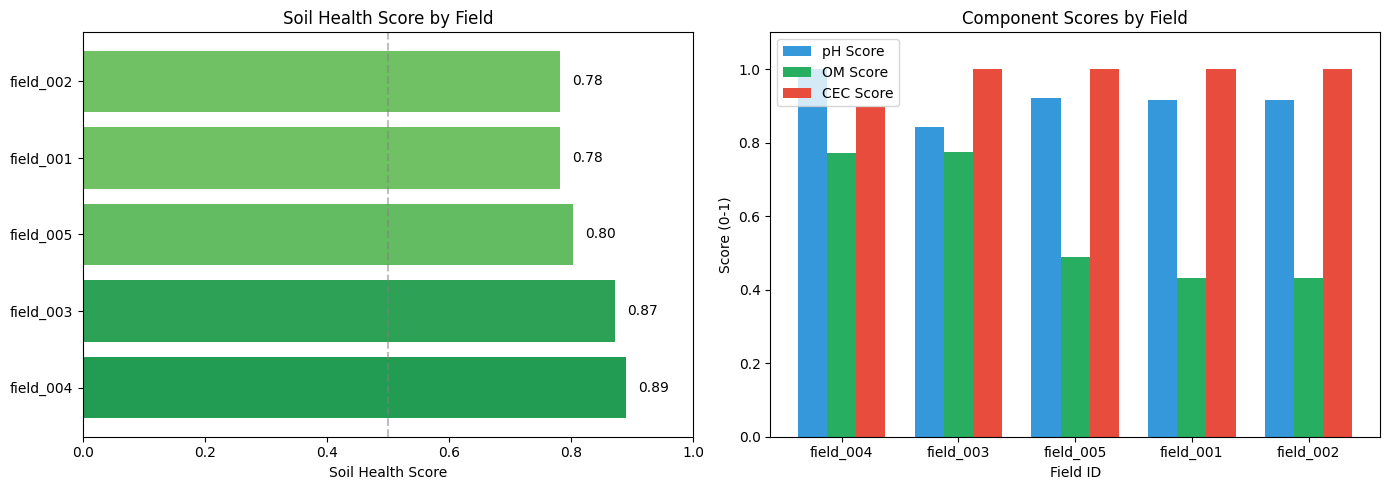


Visualization saved to: soil_health_scores.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
colors = plt.cm.RdYlGn(field_soil['soil_health_score'].values)
bars = ax1.barh(field_soil['field_id'], field_soil['soil_health_score'], color=colors)
ax1.set_xlabel('Soil Health Score')
ax1.set_title('Soil Health Score by Field')
ax1.set_xlim(0, 1)
ax1.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5, label='Midpoint')
for i, (score, field) in enumerate(zip(field_soil['soil_health_score'], field_soil['field_id'])):
    ax1.text(score + 0.02, i, f'{score:.2f}', va='center', fontsize=10)

ax2 = axes[1]
x = np.arange(len(field_soil))
width = 0.25
ax2.bar(x - width, field_soil['ph_score'], width, label='pH Score', color='#3498db')
ax2.bar(x, field_soil['om_score'], width, label='OM Score', color='#27ae60')
ax2.bar(x + width, field_soil['cec_score'], width, label='CEC Score', color='#e74c3c')
ax2.set_xlabel('Field ID')
ax2.set_ylabel('Score (0-1)')
ax2.set_title('Component Scores by Field')
ax2.set_xticks(x)
ax2.set_xticklabels(field_soil['field_id'])
ax2.legend()
ax2.set_ylim(0, 1.1)

plt.tight_layout()
plt.savefig('soil_health_scores.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nVisualization saved to: soil_health_scores.png")

## Results Summary

In [10]:
results = field_soil[['field_id', 'organic_matter_pct', 'ph', 'cec', 
                       'ph_score', 'om_score', 'cec_score', 'soil_health_score']].copy()
results.columns = ['Field ID', 'Organic Matter (%)', 'pH', 'CEC (meq/100g)',
                   'pH Score', 'OM Score', 'CEC Score', 'Soil Health Score']
results = results.round(3)

print("=" * 80)
print("SOIL HEALTH RANKINGS")
print("=" * 80)
print(results.to_string(index=False))
print("=" * 80)

print(f"\nHighest Scoring Field: {results.iloc[0]['Field ID']} ({results.iloc[0]['Soil Health Score']:.2f})")
print(f"Lowest Scoring Field:  {results.iloc[-1]['Field ID']} ({results.iloc[-1]['Soil Health Score']:.2f})")

SOIL HEALTH RANKINGS
 Field ID  Organic Matter (%)    pH  CEC (meq/100g)  pH Score  OM Score  CEC Score  Soil Health Score
field_004               3.090 6.625          22.915     1.000     0.772      0.896              0.889
field_003               3.095 6.105          26.317     0.842     0.774      1.000              0.872
field_005               1.950 6.300          26.150     0.920     0.488      1.000              0.802
field_001               1.728 6.290          27.261     0.916     0.432      1.000              0.783
field_002               1.728 6.290          27.261     0.916     0.432      1.000              0.783

Highest Scoring Field: field_004 (0.89)
Lowest Scoring Field:  field_002 (0.78)


## Save Results

In [11]:
output_path = Path('../data/soil_health_scores.csv')
output_path.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(output_path, index=False)
print(f"Results saved to: {output_path}")

Results saved to: ../data/soil_health_scores.csv
